# FFT Outliers in the four_objs Boxes

Which samples have an FFT magnitude that is statistically unlike the rest of their box?

Data: every sample of the three four_objs datasets (gastronorm, green plastic, cardboard), both `samples/` and the already quarantined `bad_samples/`. The quarantined ones are a free sanity check, because some were pulled for vibration reasons (whiteboard, partial capture).

Method: the speaker sets most of the spectrum, so all statistics run inside one (box, speaker) group. Each sample becomes per-laser band levels in dB. Every feature gets a robust z-score against the group (median / MAD), and that produces three scores per sample:

- `dlevel`: overall dB minus the group median. Catches loud or quiet captures.
- `rmsz`: RMS of the feature z-scores. Catches spectra with the wrong shape.
- `laser`: the worst laser's mean z. Catches one broken laser.

Each score is then robust-z'd again inside its group. A sample is **flagged** if any of the three is more than `T` robust SDs from the median.

That catches **mis-measured** captures. **Cleaning** needs more than that, so the notebook adds two more sections:
- Section 7, chirp timing: a direct detector for the subtle capture glitch that sits below `T`, with a threshold in milliseconds instead of SDs. It also explains why lowering `T` is the wrong tool.
- Section 9, position in the box: where in the box the signal is strong and where it tells positions apart (edges, laser wall), plus a check of whether the signal can catch label errors.

# 1 Setup

In [1]:
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent
BOXES = dict(gastronorm="2026_09_27_gastronorm_four_objs", plastic="2026_10_05_green_plastic_four_objs", cardboard="2026_10_11_cardboard_four_objs")
BAND = 30          # FFT bins per band: 1170 bins over 100-1000 Hz -> 39 bands of ~23 Hz
T = 8              # flag threshold, robust SDs
MIN_GROUP = 20     # (box, speaker) groups smaller than this are not scored
BY_DESIGN = "shifted|lid"   # layouts that change the setup on purpose: moved lasers, lid on the box
WIN = 50           # frames per envelope window: 50 / 2500 fps = 20 ms
LAG = 15           # max chirp lag searched, in windows (±300 ms)
MISTIMED_MS = 40   # |chirp lag| at or above this = mistimed capture
MIN_POS_GROUP = 50 # (box, speaker, object) groups smaller than this are left out of section 9
LASER_CENTER, LASER_WIDTH = 0.5, 0.28  # laser patch on the bottom wall, as fractions of its length (measured on image.png: dense grid at 0.37-0.65)
NEAR_WALL = 300    # px from the laser wall that counts as "near" in section 9.3

# 2 Load

`vibration/04_ffts.npz["fft"]` has shape (1, 100 lasers, 1170 freqs, x/y). Per sample, keep:

- `feat`: per-laser band means of `20 log10 |FFT|`, shape (100, 39, 2). Everything is scored on this.
- `spec`: the laser- and axis-mean dB spectrum, shape (1170,). Used only for plots.
- `env`: the time envelope of `03_clean_shifts.npy` (1, 100, 3250, 2), the band-passed and Hann-windowed displacement. It is the energy in 20 ms windows, averaged over lasers and axes, in dB, shape (65,).

Metadata: for single-object samples, `avg_com` (row, col in cropped-overhead px) becomes `row`, `col`, and their fractions of the crop, `v` and `u`.

All ~19k samples load in about a minute.

In [2]:
def read_meta(p): return {k: v for l in p.read_text().splitlines() if l.strip() for k, v in json.loads(l).items()}

rows = []
for box, d in BOXES.items():
    for sub in ["samples", "bad_samples"]:
        for p in sorted((REPO / "experiments" / d / sub).glob("*/vibration/04_ffts.npz")):
            m = read_meta(p.parents[1] / "metadata.jsonl")
            H, W = m["crop_overhead_shape"][:2]
            com = m.get("avg_com") if m.get("n_objects") == 1 and isinstance(m.get("avg_com"), list) else [np.nan, np.nan]
            rows.append(dict(box=box, sample_id=p.parents[1].name, quarantined=sub == "bad_samples", position_id=m["position_id"],
                             speaker=m["speaker"], layout=m["layout"], is_empty=bool(m.get("is_empty_box")), n_obj=m.get("n_objects"),
                             obj=next(iter(m.get("objects") or {}), None), row=com[0], col=com[1], v=com[0] / H, u=com[1] / W, H=H, W=W, path=p))
df = pd.DataFrame(rows)

def load(p):
    db = 20 * np.log10(np.abs(np.load(p)["fft"][0]) + 1e-12)
    x = np.load(p.parent / "03_clean_shifts.npy")[0]
    return db.reshape(100, -1, BAND, 2).mean(2), db.mean((0, 2)), 10 * np.log10((x ** 2).mean((0, 2)).reshape(-1, WIN).mean(1) + 1e-30)
with ThreadPoolExecutor(32) as ex: out = list(ex.map(load, df.path))
feat, spec, env = [np.stack([o[i] for o in out]) for i in range(3)]
feat = feat.reshape(len(df), -1)
freqs = np.load(df.path[0])["freqs"]
print(feat.shape, spec.shape, env.shape)
df.groupby(["box", "speaker"]).size().unstack().fillna(0).astype(int)

(19435, 7800) (19435, 1170) (19435, 65)


speaker,1,2,3,4,5,7
box,,,,,,
cardboard,1823,0,1823,30,1823,1823
gastronorm,1262,1259,1260,1259,2,1259
plastic,1435,0,1435,74,1434,1434


# 3 Scores

In [3]:
def robust_z(x): med = np.median(x); return (x - med) / (1.4826 * np.median(np.abs(x - med)))

df["n_group"] = df.groupby(["box", "speaker"]).box.transform("size")
for _, g in df[df.n_group >= MIN_GROUP].groupby(["box", "speaker"]):
    X = feat[g.index]
    Z = (X - np.median(X, 0)) / (1.4826 * np.median(np.abs(X - np.median(X, 0)), 0))
    lvl = X.mean(1)
    df.loc[g.index, "dlevel"] = lvl - np.median(lvl)
    df.loc[g.index, "rmsz"] = np.sqrt((Z ** 2).mean(1))
    df.loc[g.index, "laser"] = np.abs(Z.reshape(len(g), 100, -1).mean(2)).max(1)
for k in ["dlevel", "rmsz", "laser"]: df[k + "_z"] = df.groupby(["box", "speaker"])[k].transform(lambda x: robust_z(x.to_numpy()))
df["flag"] = (df.dlevel_z.abs() > T) | (df.rmsz_z > T) | (df.laser_z > T)
df["by_design"] = df.layout.str.contains(BY_DESIGN)
print("not scored (group too small):", df.dlevel.isna().sum())
pd.crosstab([df.box, df.quarantined], [df.by_design, df.flag]).rename_axis(columns=["by_design", "flag"])

not scored (group too small): 2


by_design              False       True       
flag                   False True  False True 
box        quarantined                        
cardboard  False        7024     6    78   125
           True           79     5     0     5
gastronorm False        6092    13    25    25
           True          130    16     0     0
plastic    False        5551     1   125    59
           True           76     0     0     0

## 3.1 Score Distributions

Grey = normal samples, blue = by-design layouts, red = quarantined. The dashed line is `T`. The y axis is a log scale so the tail stays visible.

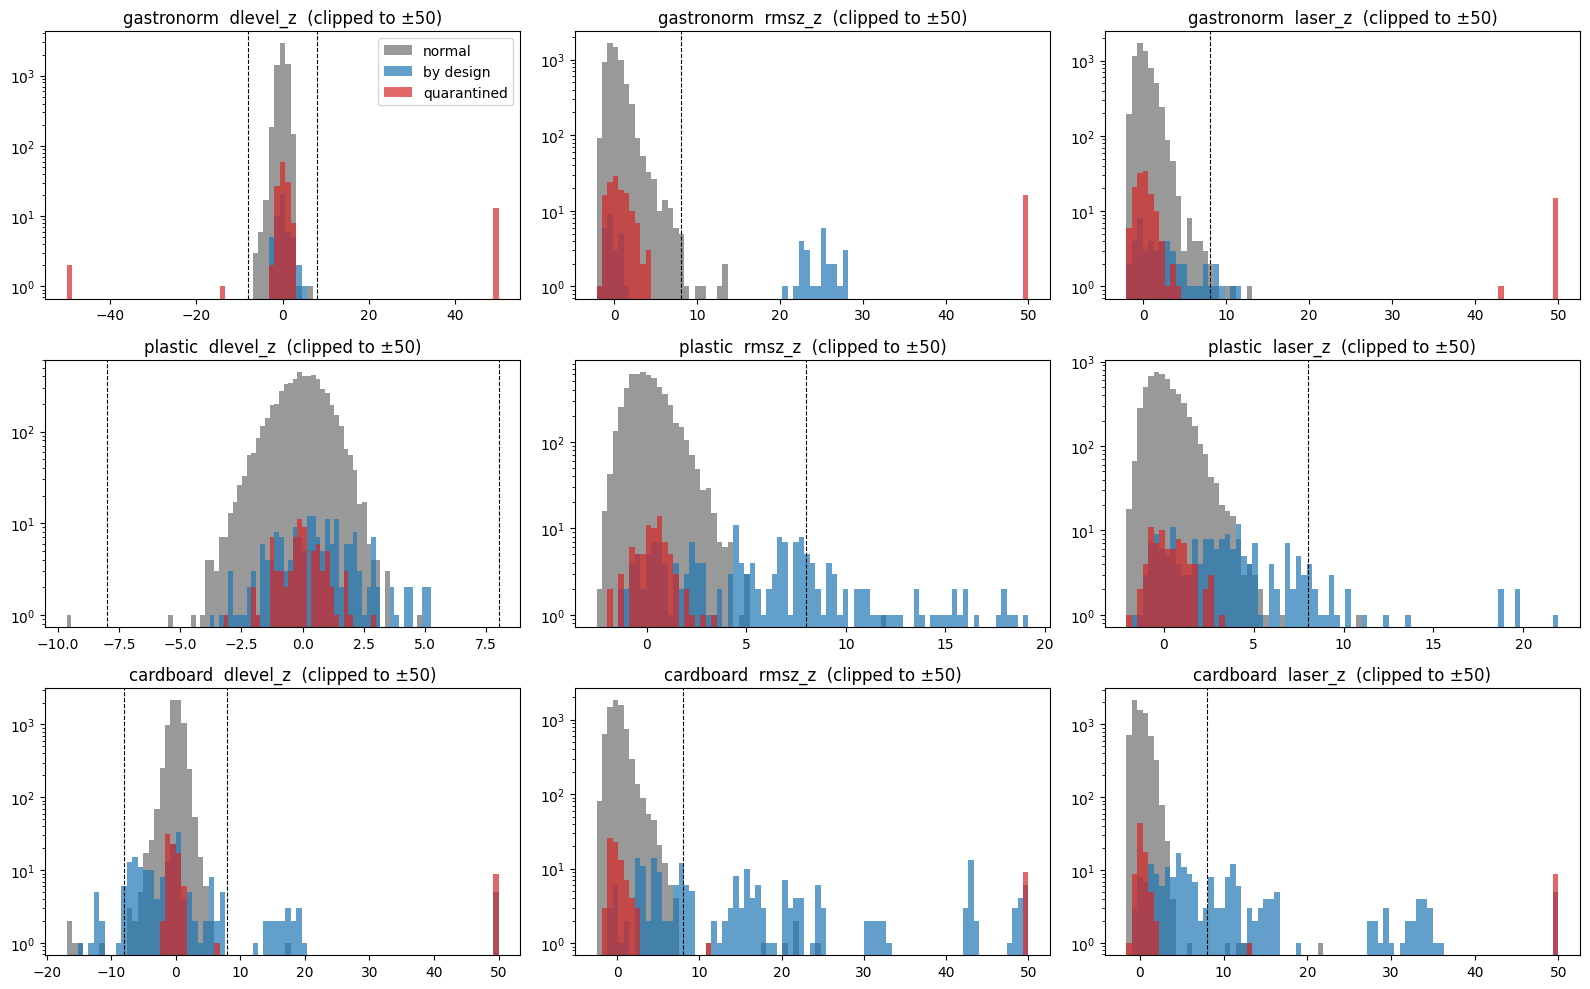

In [4]:
fig, axs = plt.subplots(3, 3, figsize=(16, 10))
for r, box in enumerate(BOXES):
    g = df[(df.box == box) & df.dlevel.notna()]
    for c, k in enumerate(["dlevel_z", "rmsz_z", "laser_z"]):
        x = g[k].clip(-50, 50)
        bins = np.linspace(x.min(), x.max(), 80)
        ax = axs[r, c]
        ax.hist(x[~g.by_design & ~g.quarantined], bins, color="0.6", label="normal")
        ax.hist(x[g.by_design], bins, color="tab:blue", alpha=.7, label="by design")
        ax.hist(x[g.quarantined], bins, color="tab:red", alpha=.7, label="quarantined")
        for t in ([-T, T] if k == "dlevel_z" else [T]): ax.axvline(t, c="k", ls="--", lw=.8)
        ax.set(yscale="log", title=f"{box}  {k}  (clipped to ±50)")
axs[0, 0].legend()
plt.tight_layout()

# 4 Sanity Check: Quarantined Samples

Most quarantined positions were pulled for image reasons (hand in frame, bad mask, mislabel), so their FFTs should look normal. Only the vibration-related ones should be flagged.

In [5]:
q = df[df.quarantined].groupby(["box", "position_id"]).agg(layout=("layout", "first"), n=("flag", "size"), n_flag=("flag", "sum"),
                                                          dlevel=("dlevel", "median"), rmsz=("rmsz", "median"))
print(f"{(q.n_flag > 0).sum()} / {len(q)} quarantined positions have a flagged sample")
q[q.n_flag > 0].round(1)

7 / 72 quarantined positions have a flagged sample


layout  n  n_flag     dlevel       rmsz
box        position_id                                              
cardboard  3781         empty-box-5  4       4  36.299999  39.400002
           4181           two-cubes  4       1   0.400000   1.000000
           4706            vase-lid  5       5  37.700001  42.400002
gastronorm 1                  empty  4       3 -20.299999  21.700001
           293            empty-box  5       5  56.700001  45.299999
           294            empty-box  5       5  56.700001  45.299999
           295                empty  4       3  56.299999  44.900002

# 5 By-Design Layouts

Moving the lasers (`*shifted*`) or putting a lid on the box (`*lid*`) changes the setup, so these samples *should* look different. This table checks that the detector sees them, and shows how big each change is in `rmsz`, where about 1 is typical.

In [6]:
d = df[df.by_design].assign(kind=lambda x: x.layout.str.replace(r"-grid.*", "", regex=True))
d.groupby(["box", "kind"]).agg(n=("flag", "size"), frac_flag=("flag", "mean"), rmsz=("rmsz", "median"), dlevel=("dlevel", "median")).round(2)

n  frac_flag  rmsz  dlevel
box        kind                                                       
cardboard  empty-laser-shifted-4           12       1.00  8.42    3.50
           vase-laser-shifted-2            36       0.47  2.34   -0.07
           vase-laser-shifted-3            36       1.00  4.72   -1.78
           vase-laser-shifted-4            24       1.00  8.51    3.12
           vase-lid                        95       0.43  2.01   -0.16
           vase-lid.                        5       0.00  1.74    0.06
gastronorm red-cube-lid                    50       0.50  2.73   -0.08
plastic    cube-shifted-lasers-1           40       0.00  1.27    0.15
           cube-shifted-lasers-2           40       0.25  1.71   -0.02
           cube-shifted-lasers-3-backside  40       0.42  1.99    0.09
           red-cube-lid                    64       0.50  1.81    0.34

# 6 New Outliers

These are the flagged samples that are neither quarantined nor by design, which makes them the actual candidates. `n_spk_flag` counts the flagged speakers at the same position. If every speaker is flagged, something physical happened at that position. If only one is, the capture itself glitched.

In [7]:
new = df[df.flag & ~df.quarantined & ~df.by_design].copy()
new["n_spk_flag"] = new.groupby(["box", "position_id"]).flag.transform("size")
new = new.join(df.groupby(["box", "position_id"]).size().rename("n_spk"), on=["box", "position_id"])
cols = ["box", "sample_id", "position_id", "speaker", "layout", "n_spk_flag", "n_spk", "dlevel", "rmsz", "laser", "dlevel_z", "rmsz_z", "laser_z"]
new.sort_values(["box", "position_id", "speaker"])[cols].round(2)

,box,sample_id,position_id,speaker,layout,n_spk_flag,n_spk,dlevel,rmsz,laser,dlevel_z,rmsz_z,laser_z
12626,cardboard,003049-3,3049,3,cube-grid-2,1,4,-4.60,4.70,3.70,-16.430000,21.920000,12.350000
13230,cardboard,003212-3,3212,3,cube-random-pos2,1,4,-4.74,4.67,3.82,-16.930000,21.760000,12.850000
13322,cardboard,003235-3,3235,3,cube-random-pos2,1,4,-4.06,4.04,3.20,-14.500000,18.030001,10.330000
15364,cardboard,003747-7,3747,7,soap-dispenser-grid-3,1,4,4.24,5.07,5.59,17.040001,24.180000,21.870001
16364,cardboard,003998-7,3998,7,candle-grid-3,1,4,-2.88,2.90,2.03,-11.570000,11.240000,6.150000
17886,cardboard,004382-3,4382,3,cylinder-200g-grid-2,1,4,-4.35,4.48,3.51,-15.530000,20.600000,11.610000
293,gastronorm,000298,60,4,red-cube-grid1,1,5,-0.60,2.26,1.05,-1.890000,8.000000,3.370000
314,gastronorm,000319,64,7,red-cube-grid1,1,5,-1.76,2.13,1.86,-5.870000,7.300000,10.910000
478,gastronorm,000483,97,4,red-cube-grid1,1,5,0.07,2.29,0.67,0.220000,8.200000,0.540000
1120,gastronorm,001150,231,1,red-cube-grid2,1,5,-2.01,2.72,1.80,-5.900000,10.670000,10.070000


## 6.1 Where in Frequency

For each new outlier: the sample's spectrum minus its group's median spectrum, smoothed over 10 bins. The grey band is ±1 std of the group, which shows normal sample-to-sample variation.

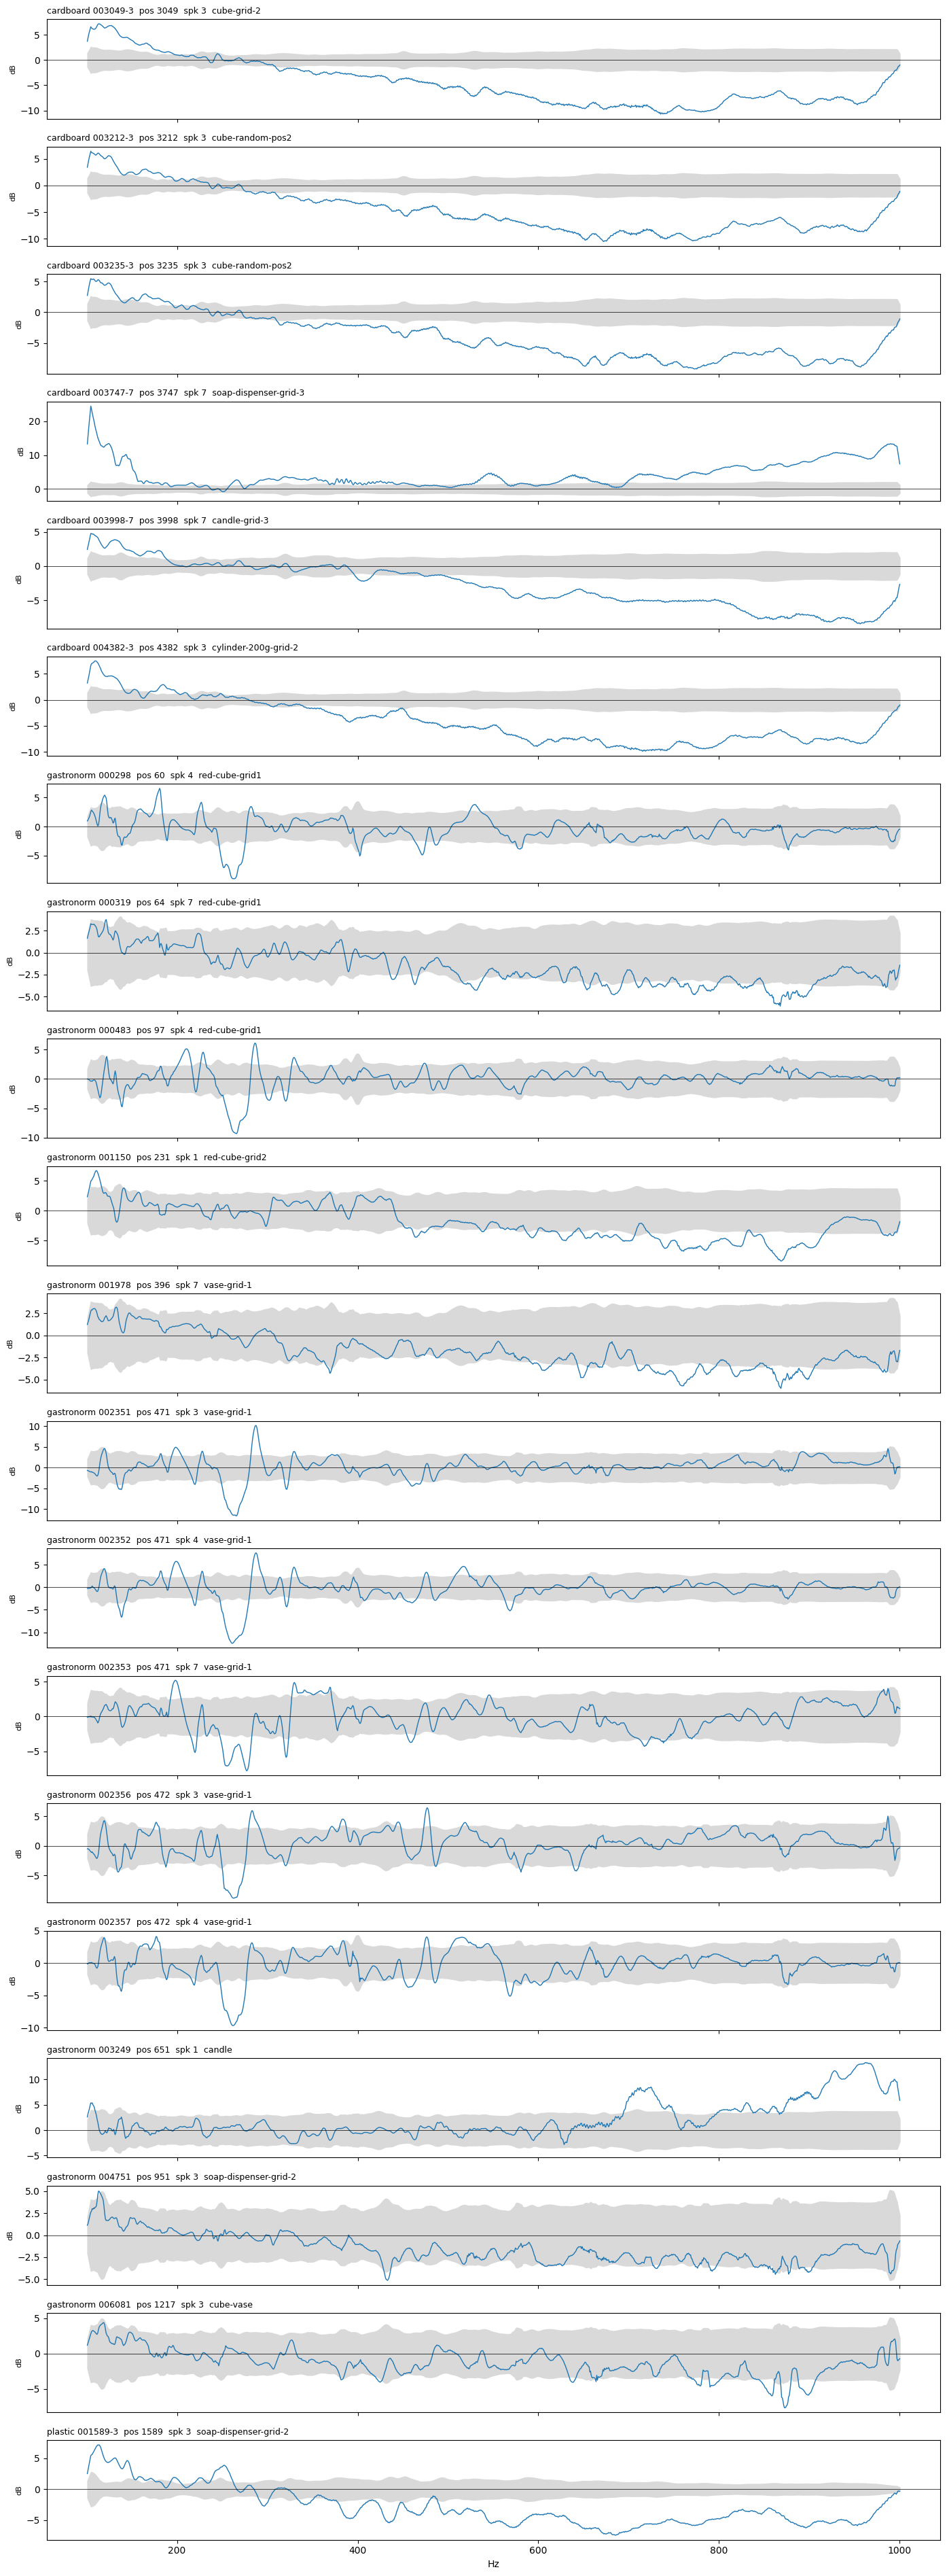

In [8]:
def smooth(a, k=10): return np.convolve(a, np.ones(k) / k, mode="same")

fig, axs = plt.subplots(len(new), 1, figsize=(14, 1.9 * len(new)), sharex=True)
for ax, (i, r) in zip(np.atleast_1d(axs), new.sort_values(["box", "position_id", "speaker"]).iterrows()):
    g = spec[df.index[(df.box == r.box) & (df.speaker == r.speaker)]]
    sd = smooth(g.std(0))
    ax.fill_between(freqs, -sd, sd, color="0.85")
    ax.plot(freqs, smooth(spec[i] - np.median(g, 0)), lw=1)
    ax.axhline(0, c="k", lw=.5)
    ax.set_ylabel("dB", fontsize=8)
    ax.set_title(f"{r.box} {r.sample_id}  pos {r.position_id}  spk {r.speaker}  {r.layout}", fontsize=9, loc="left")
np.atleast_1d(axs)[-1].set_xlabel("Hz")
plt.tight_layout()

## 6.2 Where in Time

The stimulus is a chirp, so time maps to frequency. Each panel plots the sample's `env` against its group's median envelope (unflagged samples only). A late or truncated playback shows up as missing energy at the start or end.

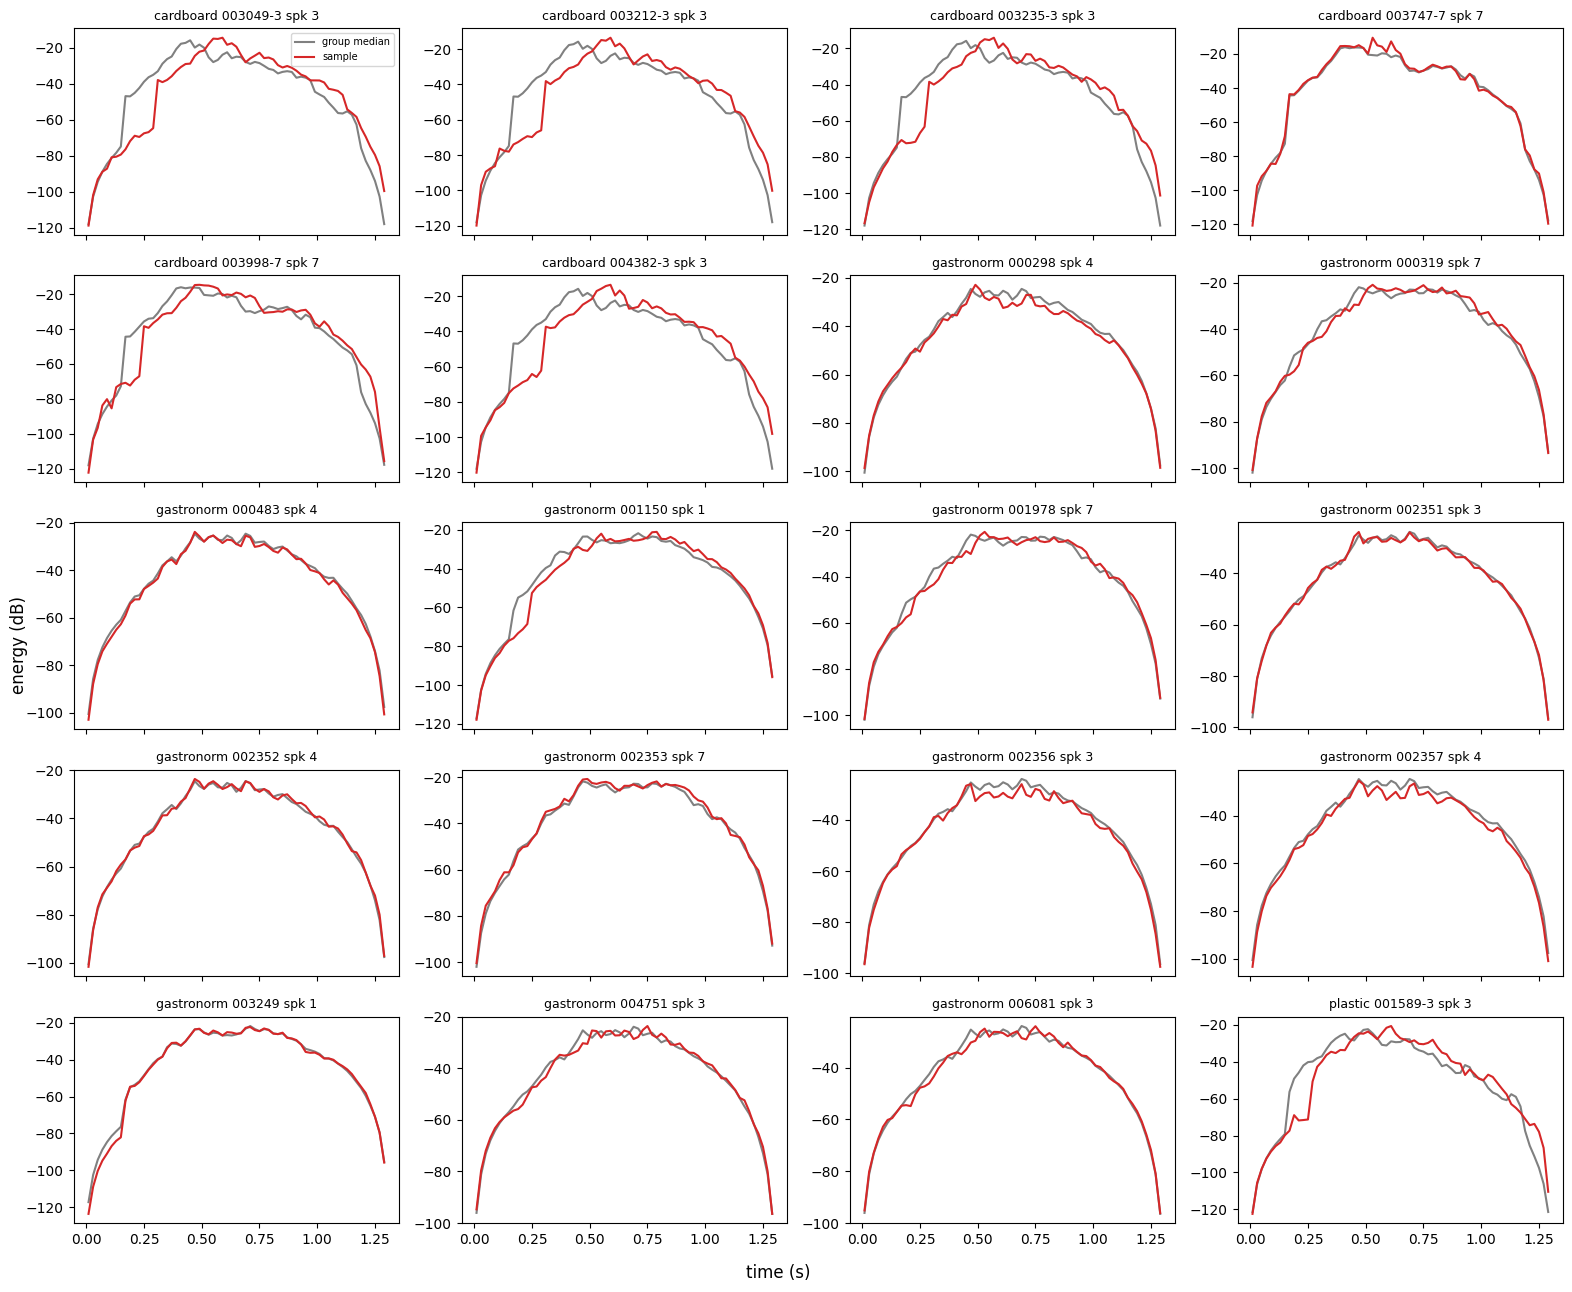

In [9]:
t = (np.arange(env.shape[1]) + .5) * WIN / 2500
fig, axs = plt.subplots(int(np.ceil(len(new) / 4)), 4, figsize=(16, 2.6 * np.ceil(len(new) / 4)), sharex=True)
for ax, (i, r) in zip(axs.flat, new.sort_values(["box", "position_id", "speaker"]).iterrows()):
    g = df[(df.box == r.box) & (df.speaker == r.speaker) & ~df.flag]
    ax.plot(t, np.median(env[g.index], 0), c="0.5", label="group median")
    ax.plot(t, env[i], c="tab:red", label="sample")
    ax.set_title(f"{r.box} {r.sample_id} spk {r.speaker}", fontsize=9)
for ax in axs.flat[len(new):]: ax.axis("off")
axs.flat[0].legend(fontsize=7)
fig.supxlabel("time (s)"); fig.supylabel("energy (dB)")
plt.tight_layout()

# 7 Chirp Timing (for Cleaning)

Section 6.2 shows that most new outliers are a **mistimed chirp**: the speaker played late, or the trigger fired early. This section measures that directly for every sample. Shift the sample's envelope by -300 to +300 ms in 20 ms steps, and take the shift that best matches its group's median envelope (least squares, edges excluded). Positive lag = the chirp came late.

The threshold has a physical meaning: one window (20 ms) is jitter, and two or more windows (≥ 40 ms) is a glitch. The table below supports that cut.

In [10]:
for _, g in df[df.n_group >= MIN_GROUP].groupby(["box", "speaker"]):
    E, ref = env[g.index], np.median(env[g.index], 0)
    err = np.stack([((np.roll(E, -l, 1) - ref)[:, LAG:-LAG] ** 2).mean(1) for l in range(-LAG, LAG + 1)], 1)
    df.loc[g.index, "lag_ms"] = (err.argmin(1) - LAG) * WIN / 2.5
df["mistimed"] = df.lag_ms.abs() >= MISTIMED_MS
print("Spectrum deviation by |lag| (lags past 60 ms grouped; these are mostly the gross failures, where lag means nothing):")
df.groupby(df.lag_ms.abs().clip(0, 80)).agg(n=("lag_ms", "size"), dlevel=("dlevel", "median"), rmsz=("rmsz", "median"),
                                             rmsz_z=("rmsz_z", "median"), flagged=("flag", "sum")).round(2)

Spectrum deviation by |lag| (lags past 60 ms grouped; these are mostly the gross failures, where lag means nothing):


,n,dlevel,rmsz,rmsz_z,flagged
lag_ms,,,,,
0.0,17325,0.02,1.00,-0.060000,108
20.0,1938,-0.34,1.08,0.440000,57
40.0,90,-1.27,1.68,4.230000,13
60.0,37,2.72,8.22,42.410000,34
80.0,43,28.74,28.27,108.080002,43


Mistimed samples that the `T = 8` capture flag missed (not quarantined, not by design). These are subtle: 1-2 dB quiet, `rmsz_z` 2-7.

In [11]:
mt = df[df.mistimed & ~df.flag & ~df.quarantined & ~df.by_design]
print(len(mt), "extra samples |", mt.groupby("box").size().to_dict(), "| by lag:", mt.lag_ms.value_counts().sort_index().to_dict())
mt.groupby(["box", "speaker"]).size().unstack().fillna(0).astype(int)

80 extra samples | {'cardboard': 51, 'gastronorm': 21, 'plastic': 8} | by lag: {40.0: 77, 60.0: 3}


speaker,1,2,3,4,5,7
box,,,,,,
cardboard,10,0,34,0,5,2
gastronorm,1,13,4,3,0,0
plastic,5,0,1,0,1,1


## 7.1 Why Not Just Lower `T`?

`T` asks whether a sample is far from everything else of its speaker. Different objects and positions really do sit several SDs out, because that difference **is** the signal the model learns. Lowering `T` mostly removes real data. The sweep shows how many normal samples each `T` flags, and how few of them the timing detector can explain.

In [12]:
sweep = []
for t in [3, 4, 5, 6, 8, 12]:
    f = ((df.dlevel_z.abs() > t) | (df.rmsz_z > t) | (df.laser_z > t)) & ~df.by_design & ~df.quarantined
    sweep.append(dict(T=t, flagged_normal=f.sum(), of_which_mistimed=(f & df.mistimed).sum(), unexplained=(f & ~df.mistimed).sum()))
pd.DataFrame(sweep).set_index("T")

,flagged_normal,of_which_mistimed,unexplained
T,,,
3,648,81,567
4,271,62,209
5,120,40,80
6,66,32,34
8,20,11,9
12,8,4,4


# 8 Recording Order

`rmsz` against recording order inside each box. A run of high values would mean drift or a bad stretch of the session rather than one-off glitches.

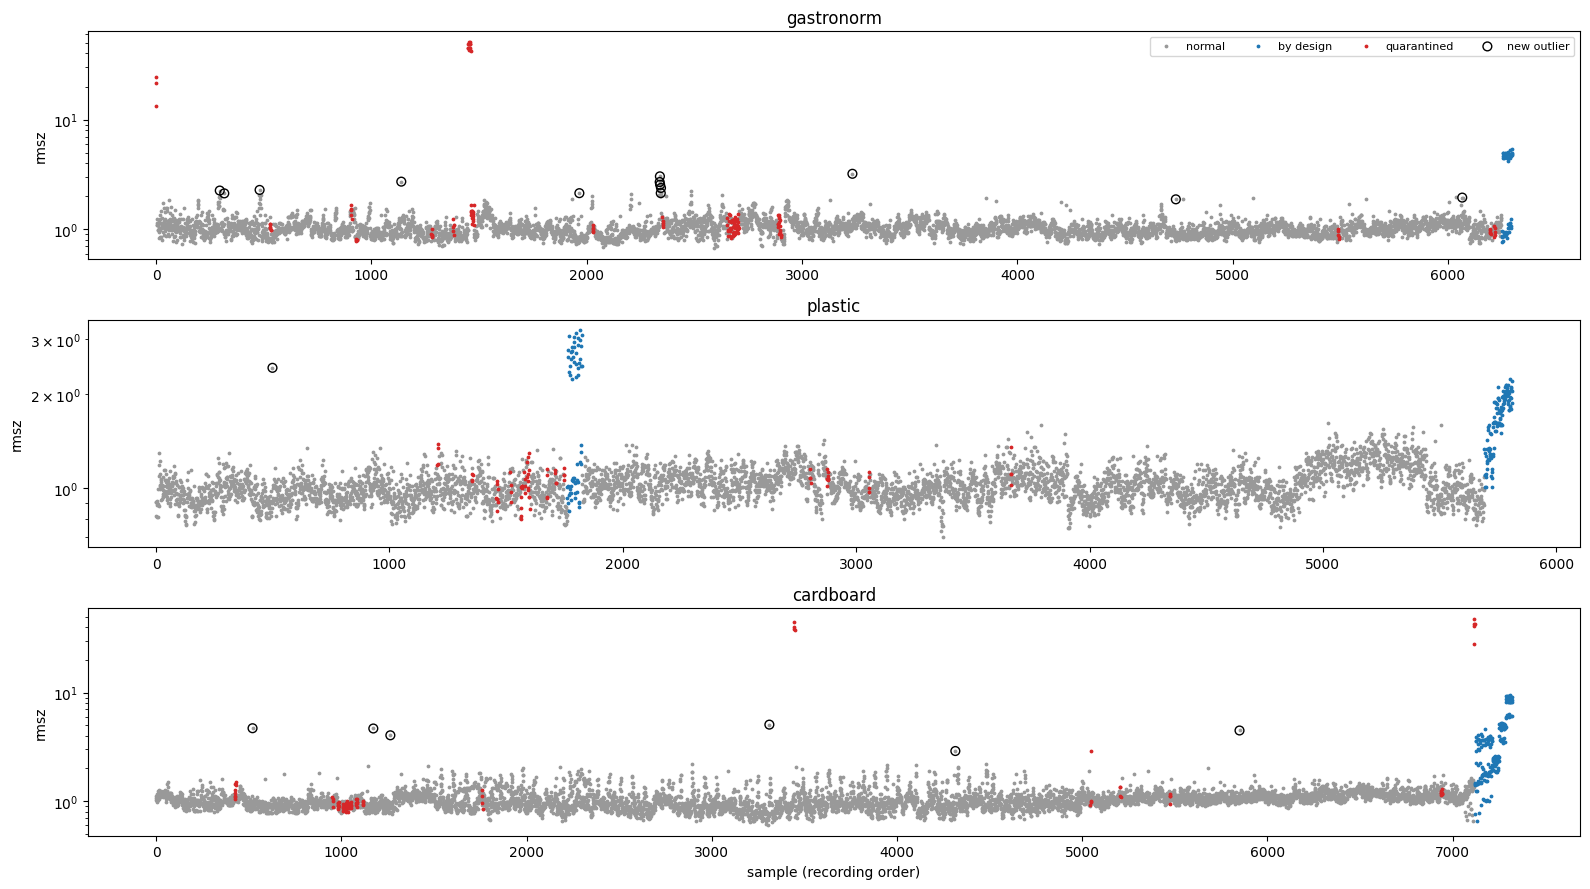

In [13]:
fig, axs = plt.subplots(3, 1, figsize=(16, 9))
for ax, box in zip(axs, BOXES):
    g = df[(df.box == box) & df.rmsz.notna()].sort_values("sample_id").reset_index(drop=True)
    for (lab, c), m in zip([("normal", "0.6"), ("by design", "tab:blue"), ("quarantined", "tab:red")],
                           [~g.by_design & ~g.quarantined, g.by_design & ~g.quarantined, g.quarantined]):
        ax.scatter(g.index[m], g.rmsz[m], s=3, c=c, label=lab)
    n = g[g.flag & ~g.by_design & ~g.quarantined]
    ax.scatter(n.index, n.rmsz, s=40, facecolors="none", edgecolors="k", label="new outlier")
    ax.set(yscale="log", title=box, ylabel="rmsz")
axs[0].legend(ncol=4, fontsize=8)
axs[-1].set_xlabel("sample (recording order)")
plt.tight_layout()

# 9 Position in the Box

Where in the box is the signal strong, and where does it tell positions apart? This uses single-object samples that are clean by sections 3 and 7. Every comparison stays inside one (box, speaker, object) group.

- `dlevel`: overall level vs the (box, speaker) median, in dB.
- `cue`: how much the object changes the spectrum. It is the RMS robust z of `feat` against the empty-box captures of the same (box, speaker), clipped to ±10.
- `loc_err`: how well the signal tells positions apart. For each sample, find its 1-nearest neighbour in feature space inside its group, and take the px distance between the two CoMs. This is a model-free proxy for localization performance. A plain 1-NN has no inward pull at the edges, which averaging would add.
- `loc_floor`: the px distance to the nearest other position. A perfect signal still can't beat this.
- `loc_ratio = loc_err / loc_floor`: localization error in units of grid spacing. Where positions are sampled more densely, raw `loc_err` drops even if the signal is no better. Dividing by the spacing removes that, so `loc_ratio` is the fair measure of **how distinguishable positions are**. 1 means the FFT points to the nearest possible neighbour.
- `sens`: how much the FFT changes per move. It is the median RMS feature distance to samples 40-90 px away. If noise is the same across the box, higher means more distinguishable.

Geometry: the overhead images show the laser dots on the wall at the **bottom** of the crop in all three boxes. The lasers don't cover that whole wall, though. They cover a centered patch (`LASER_CENTER`, `LASER_WIDTH`). In a front photo of the cardboard wall from the laser camera's side (`image.png` at the repo root), the dense dot grid spans 0.37-0.65 of the wall's length; the sparse dots across the rest of the wall are diffraction spill. The same fraction is assumed for the other boxes: the projector is fixed, the boxes are about the same width (crop W 1287-1365 px), and the spill seen from above is centered at 0.50-0.54 in all three. Distances, in px:
- `d_patch`: to the laser patch, a segment on the bottom wall.
- `d_laser = H - row`: to the laser wall anywhere along it.
- `d_side = min(col, W - col)`: to the nearest left/right wall, free of the laser wall.
- `along = |col - LASER_CENTER·W| / W`: sideways offset from the patch center, as a fraction of the width.

These are crop edges, which sit close to the box walls.

In [14]:
pos = df[(df.n_obj == 1) & df.row.notna() & ~df.by_design & ~df.flag & ~df.mistimed].copy()
pos = pos[pos.groupby(["box", "speaker", "obj"]).box.transform("size") >= MIN_POS_GROUP]

for (box, spk), e in df[df.is_empty & ~df.flag & ~df.mistimed].groupby(["box", "speaker"]):
    E = feat[e.index]
    med, mad = np.median(E, 0), 1.4826 * np.median(np.abs(E - np.median(E, 0)), 0)
    g = pos[(pos.box == box) & (pos.speaker == spk)]
    pos.loc[g.index, "cue"] = np.sqrt((np.clip((feat[g.index] - med) / mad, -10, 10) ** 2).mean(1))

for _, g in pos.groupby(["box", "speaker", "obj"]):
    X = feat[g.index]
    Z = np.clip((X - np.median(X, 0)) / (1.4826 * np.median(np.abs(X - np.median(X, 0)), 0)), -10, 10)
    P = g[["row", "col"]].to_numpy()
    Df, Dp = cdist(Z, Z), cdist(P, P)
    np.fill_diagonal(Df, np.inf); np.fill_diagonal(Dp, np.inf)
    pos.loc[g.index, "loc_err"] = np.linalg.norm(P[Df.argmin(1)] - P, axis=1)
    band = (Dp >= 40) & (Dp < 90)
    pos.loc[g.index, "sens"] = [np.median(Df[i, band[i]]) / np.sqrt(Z.shape[1]) if band[i].sum() >= 3 else np.nan for i in range(len(g))]
    pos.loc[g.index, "loc_floor"] = Dp.min(1)
    np.fill_diagonal(Dp, np.nan)
    pos.loc[g.index, "loc_chance"] = np.nanmean(Dp, 1)

pos["loc_ratio"] = pos.loc_err / pos.loc_floor
pos["d_laser"], pos["d_side"] = pos.H - pos.row, np.minimum(pos.col, pos.W - pos.col)
pos["along"] = (pos.col - LASER_CENTER * pos.W).abs() / pos.W
pos["d_patch"] = np.hypot(np.maximum(pos.along - LASER_WIDTH / 2, 0) * pos.W, pos.d_laser)
clean = pos[~pos.quarantined]
print(len(clean), "samples")
clean.groupby(["obj", "box"])[["loc_err", "loc_floor", "loc_ratio", "loc_chance", "cue"]].median().unstack().round(1)

15830 samples


loc_err                    loc_floor                     \
box            cardboard gastronorm plastic cardboard gastronorm plastic   
obj                                                                        
candle              69.7       49.6    27.3      17.9       25.7    13.6   
coffee pot           NaN        NaN    57.7       NaN        NaN    39.9   
cylinder           238.2        NaN     NaN      26.0        NaN     NaN   
red-cube            88.0       78.5    24.7      19.6       25.8    15.2   
soap dispenser      73.1       65.1    28.7      17.0       25.6    17.8   
vase                71.5       44.0    38.2      23.0       35.6    26.9   

               loc_ratio                    loc_chance                     \
box            cardboard gastronorm plastic  cardboard gastronorm plastic   
obj                                                                         
candle               3.3        1.8     1.4      393.9      383.3   355.0   
coffee pot           NaN        NaN     1.0        NaN        NaN   352.4   
cylinder             8.8        NaN     NaN      453.6        NaN     NaN   
red-cube             5.4        2.9     1.2      427.2      446.5   371.4   
soap dispenser       4.4        2.2     1.3      421.3      436.0   376.7   
vase                 3.0        1.2     1.2      454.0      440.7   367.8   

                     cue                     
box            cardboard gastronorm plastic  
obj                                          
candle               1.9        2.6     3.8  
coffee pot           NaN        NaN     3.6  
cylinder             2.9        NaN     NaN  
red-cube             1.9        2.4     3.7  
soap dispenser       2.3        2.5     3.7  
vase                 2.0        2.6     3.6

## 9.1 Maps

The median of each metric over a 6×6 grid of CoM positions, pooled over speakers and objects. The laser wall is at the bottom of each map, and the green bar marks the laser patch. **Distinguishability is the last two columns** (lower `loc_ratio` and higher `sens` = better). Level is amplitude only.

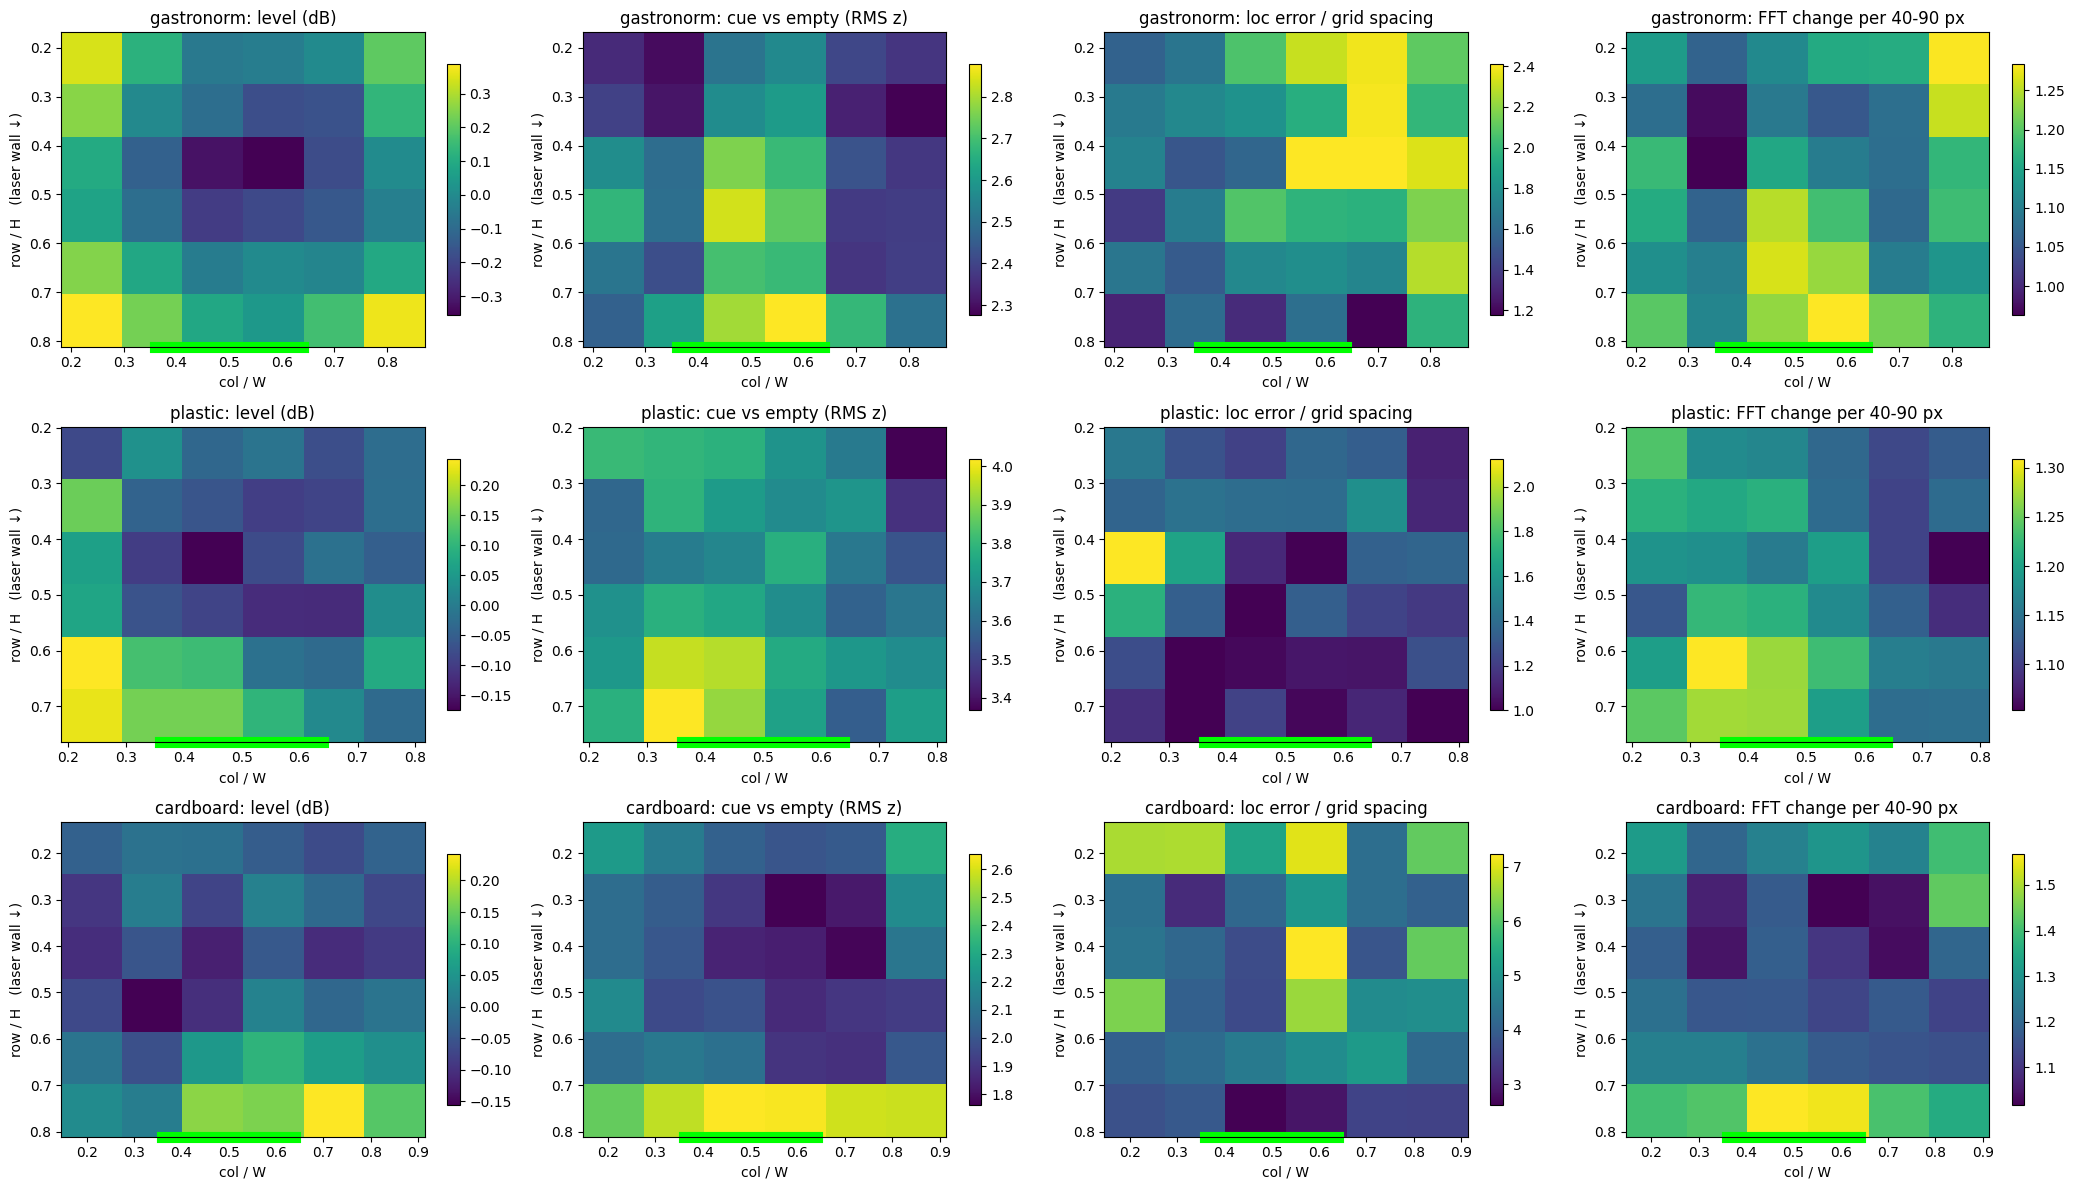

In [15]:
metrics = dict(dlevel="level (dB)", cue="cue vs empty (RMS z)", loc_ratio="loc error / grid spacing", sens="FFT change per 40-90 px")
fig, axs = plt.subplots(3, 4, figsize=(21, 12))
for r, box in enumerate(BOXES):
    g = clean[clean.box == box]
    ub, vb = np.linspace(g.u.min(), g.u.max(), 7), np.linspace(g.v.min(), g.v.max(), 7)
    g = g.assign(ub=pd.cut(g.u, ub, include_lowest=True, labels=False), vb=pd.cut(g.v, vb, include_lowest=True, labels=False))
    for c, (k, title) in enumerate(metrics.items()):
        M = g.pivot_table(index="vb", columns="ub", values=k, aggfunc="median").reindex(index=range(6), columns=range(6))
        im = axs[r, c].imshow(M, extent=(ub[0], ub[-1], vb[-1], vb[0]), aspect="auto")
        plt.colorbar(im, ax=axs[r, c], shrink=.8)
        axs[r, c].plot([LASER_CENTER - LASER_WIDTH / 2, LASER_CENTER + LASER_WIDTH / 2], [vb[-1]] * 2, c="lime", lw=8, clip_on=False)
        axs[r, c].set(title=f"{box}: {title}", xlabel="col / W", ylabel="row / H   (laser wall ↓)")
plt.tight_layout()

## 9.2 Edges and the Laser Wall

The median of each metric in 8 quantile bins of distance.

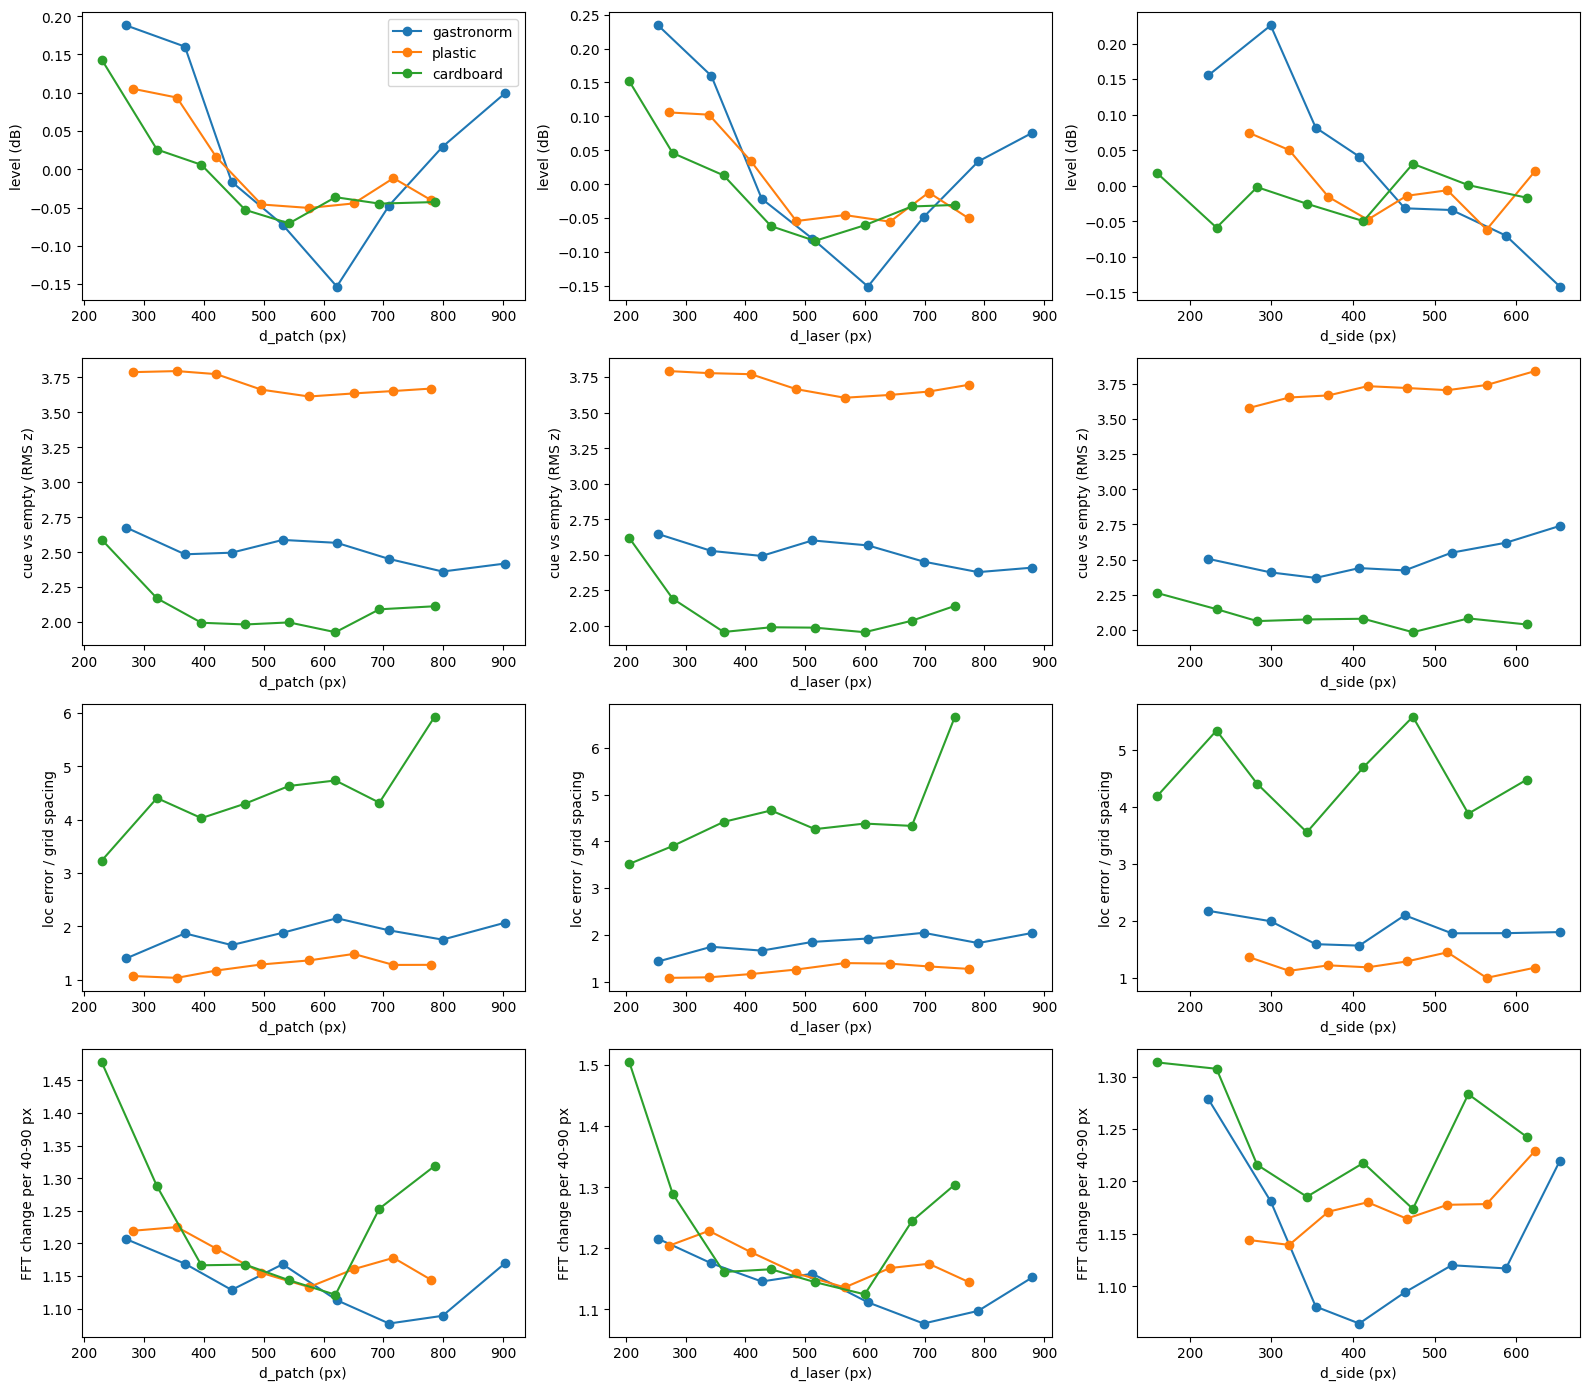

In [16]:
dists = ["d_patch", "d_laser", "d_side"]
fig, axs = plt.subplots(4, 3, figsize=(16, 14))
for r, k in enumerate(metrics):
    for c, d in enumerate(dists):
        for j, box in enumerate(BOXES):
            g = clean[clean.box == box]
            b = g.groupby(pd.qcut(g[d], 8, duplicates="drop"), observed=True)
            x = [i.mid for i in b.groups]
            axs[r, c].plot(x, b[k].median().values, "o-", c=f"C{j}", label=box)
        axs[r, c].set(xlabel=f"{d} (px)", ylabel=metrics[k])
axs[0, 0].legend()
plt.tight_layout()

In [17]:
print("Spearman rho, per box. Negative = the metric grows closer to that wall.")
pd.DataFrame({(box, k): {d: spearmanr(g[d], g[k], nan_policy="omit")[0] for d in dists} for box, g in clean.groupby("box") for k in metrics}).round(2)

Spearman rho, per box. Negative = the metric grows closer to that wall.


cardboard                       gastronorm                        \
           dlevel   cue loc_ratio  sens     dlevel   cue loc_ratio  sens   
d_patch     -0.16 -0.13      0.12 -0.14      -0.11 -0.14      0.08 -0.12   
d_laser     -0.17 -0.15      0.12 -0.16      -0.14 -0.13      0.08 -0.14   
d_side       0.03 -0.08     -0.03 -0.05      -0.34  0.19     -0.02 -0.09   

        plastic                        
         dlevel   cue loc_ratio  sens  
d_patch   -0.14 -0.14      0.08 -0.19  
d_laser   -0.15 -0.13      0.08 -0.17  
d_side    -0.09  0.22     -0.05  0.17

## 9.3 In Front of the Laser Patch, or Just Near the Wall?

Near the laser wall (`d_laser < NEAR_WALL`), samples are split into those in front of the patch (`along < LASER_WIDTH / 2`) and those beside it. If only the patch mattered, "beside" would look like "far".

In [18]:
clean["zone"] = np.where(clean.d_laser >= NEAR_WALL, "far from wall", np.where(clean.along < LASER_WIDTH / 2, "near wall, in front of patch", "near wall, beside patch"))
clean.groupby(["box", "zone"]).agg(n=("loc_ratio", "size"), loc_ratio=("loc_ratio", "median"), sens=("sens", "median"), cue=("cue", "median")).round(2)

n  loc_ratio  sens   cue
box        zone                                                     
cardboard  far from wall                 4541       4.65  1.19  2.01
           near wall, beside patch        802       3.55  1.37  2.43
           near wall, in front of patch   463       3.34  1.50  2.57
gastronorm far from wall                 4582       1.88  1.13  2.49
           near wall, beside patch        405       1.43  1.19  2.56
           near wall, in front of patch   287       1.42  1.23  2.81
plastic    far from wall                 4216       1.25  1.17  3.68
           near wall, beside patch        267       1.00  1.19  3.77
           near wall, in front of patch   267       1.09  1.22  3.82

## 9.4 Can the Signal Catch Label Errors?

If a position's FFT disagrees with its label (wrong object, wrong mask, hand in frame), its 1-NN neighbour should land far away. `loc_z` is the robust z of `loc_err` inside its group, and this checks it against the quarantined positions, whose reasons are in `bad_samples/README.md`.

In [19]:
pos["loc_z"] = pos.groupby(["box", "speaker", "obj"]).loc_err.transform(lambda x: robust_z(x.to_numpy()))
q = pos[pos.quarantined].groupby(["box", "position_id"]).agg(layout=("layout", "first"), obj=("obj", "first"), loc_err=("loc_err", "median"), loc_z=("loc_z", "median"))
c = pos[~pos.quarantined].groupby(["box", "position_id"]).loc_z.median()
print(f"positions with median loc_z > 3: quarantined {(q.loc_z > 3).mean():.0%} ({(q.loc_z > 3).sum()}/{len(q)}), clean {(c > 3).mean():.1%}")
q.sort_values("loc_z", ascending=False).round(2)

positions with median loc_z > 3: quarantined 18% (10/56), clean 2.6%


layout             obj  loc_err  \
box        position_id                                                      
cardboard  3198                 cube-random-pos2        red-cube   432.84   
gastronorm 474                       vase-grid-1            vase   139.96   
cardboard  3164         cube-different-rotations        red-cube   431.57   
           3165         cube-different-rotations        red-cube   401.82   
           3182         cube-different-rotations        red-cube   343.77   
gastronorm 582                         empty-box            vase   112.89   
plastic    1829                coffee-pot-grid-1      coffee pot   222.26   
cardboard  3176         cube-different-rotations        red-cube   231.67   
           3157         cube-different-rotations        red-cube   225.30   
plastic    1883                coffee-pot-grid-2      coffee pot   167.14   
cardboard  3171         cube-different-rotations        red-cube   231.13   
           3189         cube-different-rotations        red-cube   167.48   
           3178         cube-different-rotations        red-cube   160.89   
gastronorm 581                         empty-box            vase    59.84   
           279               red-cube-grid3_test        red-cube   111.22   
cardboard  3190         cube-different-rotations        red-cube   151.78   
plastic    2183                      vase-grid-1            vase    50.55   
           1864                coffee-pot-grid-1      coffee pot    84.15   
gastronorm 409                       vase-grid-1            vase    56.10   
           534                       vase-grid-1            vase    52.96   
           539                       vase-grid-1            vase    51.85   
plastic    1766          soap-dispenser-sideways  soap dispenser    38.63   
cardboard  3180         cube-different-rotations        red-cube   108.68   
plastic    1892                coffee-pot-grid-2      coffee pot    74.64   
cardboard  4288                   cylinder-1000g        cylinder   292.28   
           3175         cube-different-rotations        red-cube   104.76   
plastic    2184                      vase-grid-1            vase    44.81   
gastronorm 544                       vase-grid-1            vase    48.62   
plastic    1844                coffee-pot-grid-1      coffee pot    66.10   
           1856                coffee-pot-grid-1      coffee pot    69.03   
gastronorm 541                       vase-grid-1            vase    47.28   
           540                       vase-grid-1            vase    47.28   
           189                    red-cube-grid2        red-cube    83.36   
           108                    red-cube-grid1        red-cube    82.88   
plastic    1855                coffee-pot-grid-1      coffee pot    61.45   
gastronorm 543                       vase-grid-1            vase    45.92   
           542                       vase-grid-1            vase    45.92   
plastic    1863                coffee-pot-grid-1      coffee pot    58.37   
           1830                coffee-pot-grid-1      coffee pot    58.90   
           1901                coffee-pot-grid-2      coffee pot    59.27   
           1862                coffee-pot-grid-1      coffee pot    50.85   
gastronorm 537                       vase-grid-1            vase    39.94   
           107                    red-cube-grid1        red-cube    69.01   
cardboard  3026                      cube-grid-2        red-cube    71.32   
gastronorm 536                       vase-grid-1            vase    37.55   
plastic    2165                    candle-grid-3          candle    12.87   
cardboard  3025                      cube-grid-2        red-cube    66.14   
plastic    1859                coffee-pot-grid-1      coffee pot    29.93   
cardboard  3359                      vase-grid-1            vase    40.37   
gastronorm 259               red-cube-grid3_test        red-cube    38.39   
           298                        

Positions that are not quarantined but have a median `loc_z > 3` go on a **review** list. Look at their overhead images before dropping them, because this score also fires on rare, legitimately different setups.

In [20]:
review = pos[~pos.quarantined].groupby(["box", "position_id"]).agg(layout=("layout", "first"), obj=("obj", "first"), n_spk=("loc_z", "size"),
                                                                    loc_err=("loc_err", "median"), loc_z=("loc_z", "median"))
review = review[review.loc_z > 3].sort_values("loc_z", ascending=False)
print(len(review), "positions to review:", review.groupby("box").size().to_dict())
review.round(2)

96 positions to review: {'cardboard': 62, 'gastronorm': 25, 'plastic': 9}


layout             obj  n_spk  loc_err  \
box        position_id                                                          
gastronorm 283            red-cube-grid3_test        red-cube      5   873.74   
           292            red-cube-grid3_test        red-cube      5   721.55   
           500                    vase-grid-1            vase      5   294.28   
cardboard  4705         vase-unseeen-speaker4            vase      4   503.47   
           4696         vase-unseeen-speaker4            vase      4   357.05   
...                                       ...             ...    ...      ...   
plastic    1849             coffee-pot-grid-1      coffee pot      4   158.26   
           1696         soap-dispenser-grid-3  soap dispenser      4    95.11   
cardboard  4019                 candle-grid-3          candle      4   138.24   
           3145             cube-random_poses        red-cube      4   248.52   
           4066                 candle-grid-3          candle      4   138.01   

                        loc_z  
box        position_id         
gastronorm 283          30.55  
           292          24.63  
           500          16.98  
cardboard  4705         16.40  
           4696         10.84  
...                       ...  
plastic    1849          3.09  
           1696          3.09  
cardboard  4019          3.06  
           3145          3.04  
           4066          3.01  

[96 rows x 5 columns]

# 10 Speaker 1: Disturbance from Placing the Object

Recording order per position: wait `hand_delay` (0.17 s), take the overhead photo, then record speaker 1, then the others with 0.1 s gaps. Anything set off by the hand (a breeze, the knock of setting the object down, the box rocking) can only land in **speaker 1**.

The clean shifts are band-passed to 100-1000 Hz, which would hide a slow disturbance, so this uses the **raw** `02_raw_shifts.npy` (100, 3250, 2). Per 0.1 s window (13 windows), it measures power below 90 Hz (`low`, under the chirp band) and in 100-1000 Hz (`band`, what the FFT keeps), averaged over lasers and axes. Inside each position: speaker 1 minus the median of the later speakers, in dB. Empty-box positions are the control, because no object is placed there.

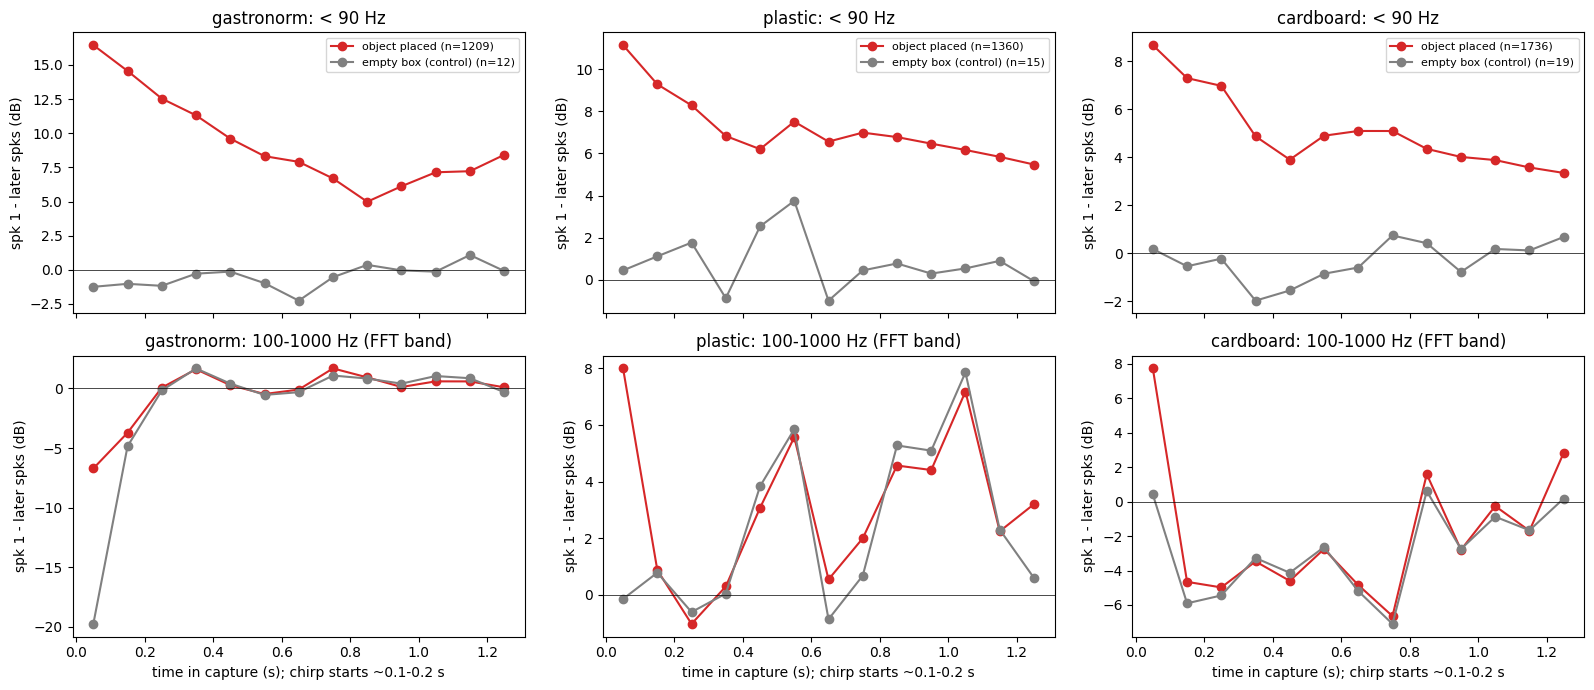

In [21]:
def raw_bands(p):
    x = np.load(p.parent / "02_raw_shifts.npy")
    w = (x - x.mean(1, keepdims=True)).reshape(100, 13, 250, 2)
    P = np.abs(np.fft.rfft(w - w.mean(2, keepdims=True), axis=2)) ** 2          # 10 Hz bins
    return 10 * np.log10(np.stack([P[:, :, 1:9].sum(2), P[:, :, 10:101].sum(2)], -1).mean((0, 2)))
with ThreadPoolExecutor(32) as ex: raw = np.stack(list(ex.map(raw_bands, df.path)))   # (N, 13, [low, band])

rows = []
for (box, pid), g in df[~df.quarantined & ~df.by_design].groupby(["box", "position_id"]):
    if 1 not in g.speaker.values or len(g) < 3: continue
    diff = raw[g.index[g.speaker == 1][0]] - np.median(raw[g.index[g.speaker != 1]], 0)
    rows.append(dict(box=box, position_id=pid, layout=g.layout.iloc[0], is_empty=g.is_empty.iloc[0], low=diff[:, 0], band=diff[:, 1]))
s1 = pd.DataFrame(rows)

t13 = np.arange(13) * .1 + .05
fig, axs = plt.subplots(2, 3, figsize=(16, 7), sharex=True)
for c, box in enumerate(BOXES):
    for r, k in enumerate(["low", "band"]):
        for emp, lab, col in [(False, "object placed", "tab:red"), (True, "empty box (control)", "0.5")]:
            g = s1[(s1.box == box) & (s1.is_empty == emp)]
            axs[r, c].plot(t13, np.median(np.stack(g[k]), 0), "o-", c=col, label=f"{lab} (n={len(g)})")
        axs[r, c].axhline(0, c="k", lw=.5)
        axs[r, c].set(title=f"{box}: {'< 90 Hz' if k == 'low' else '100-1000 Hz (FFT band)'}", ylabel="spk 1 - later spks (dB)")
for ax in axs[0]: ax.legend(fontsize=8)
for ax in axs[1]: ax.set_xlabel("time in capture (s); chirp starts ~0.1-0.2 s")
plt.tight_layout()

**Breeze or placement?** A breeze from the hand shouldn't depend on what was put down. A knock or rocking from setting the object down should grow with the object's weight and with the number of objects placed. `low_early` is the speaker-1 excess below 90 Hz over the first 0.3 s.

In [22]:
s1["low_early"] = s1.low.map(lambda a: a[:3].mean())
s1["kind"] = s1.layout.str.replace(r"-grid.*|\.$", "", regex=True)
k = s1[~s1.is_empty].groupby(["box", "kind"]).low_early.agg(["size", "median"])
k[k["size"] >= 20].round(1)

size     median
box        kind                                     
cardboard  candle                     289   5.400000
           cube                       204   5.100000
           cube-different-rotations    25   2.100000
           cube-random-pos2            49   3.000000
           cube-random_poses           26   3.400000
           cube-vase                  100  14.800000
           cylinder-1000g              34  15.900000
           cylinder-100g               43   6.100000
           cylinder-200g               49   7.600000
           cylinder-500g               50  13.500000
           soap-dispenser             272   8.300000
           soap-dispenser-rotated     105   9.600000
           soap-dispenser-rotated-2    41  10.700000
           two-cubes                   98  15.400000
           vase                       257   7.300000
gastronorm candle                     260  12.500000
           cube-vase                   49  21.000000
           red-cube                   281  10.600000
           soap-dispenser             245  15.000000
           two-cubes                   72  19.299999
           vase                       268  16.900000
plastic    candle                     253   7.800000
           coffee-pot                  86   7.900000
           cube-5-speakers             40  12.500000
           cube-box                   252  11.200000
           cube-vase                   49  14.100000
           soap-dispenser             295   7.400000
           two-cubes                   80  12.900000
           vase                       256  11.400000

**Does it hurt the FFT?** If it did, speaker 1 would be the hardest speaker to localize from. `loc_ratio` by speaker (section 9, lower = more distinguishable):

In [23]:
clean.groupby(["box", "speaker"]).loc_ratio.median().unstack().round(2)

speaker,1,2,3,4,5,7
box,,,,,,
cardboard,4.02,NaN,4.61,NaN,4.80,4.42
gastronorm,1.78,1.78,1.94,1.79,NaN,1.79
plastic,1.07,NaN,1.28,NaN,1.22,1.37


# 11 Save

In [24]:
runs = REPO / "notebooks" / "runs"
df[df.flag].drop(columns="path").to_csv(runs / "96_fft_outliers.csv", index=False)
drop = df[(df.flag | df.mistimed) & ~df.by_design & ~df.quarantined]
drop.drop(columns="path").to_csv(runs / "96_drop.csv", index=False)
review.to_csv(runs / "96_review_positions.csv")
print(df.flag.sum(), "flagged rows |", len(drop), "rows to drop for cleaning:", drop.groupby("box").size().to_dict())

255 flagged rows | 100 rows to drop for cleaning: {'cardboard': 57, 'gastronorm': 34, 'plastic': 9}


# 12 Findings

Results at `T = 8`, from the run on 2026-10-12 (the cardboard `bad_samples/` was being filled at the same time, so quarantine counts can shift).

**Gross outliers: all already quarantined.** Each one is 20-60 dB off, with `rmsz` 13-51 against a typical value of about 1:
- gastronorm positions 293-295 (on the whiteboard): about +57 dB, every speaker.
- gastronorm position 1 (no overhead image): about -20 dB.
- cardboard 3781 (`empty-box-5`) and 4706 (`vase-lid`): about +37 dB, every speaker, with exactly-zero FFT bins on a few lasers.
The other 62 quarantined positions look normal, which fits their image-only reasons.

**Plastic is clean.** Every sample is within 1.8 dB of its group. The one candidate (1589-3) is the chirp-timing glitch below. The only structure is slow drift over the session (section 8).

**New outliers (20 samples), in three kinds:**
1. **Late chirp** (cardboard 3049-3, 3212-3, 3235-3, 4382-3, 3998-7; plastic 1589-3; gastronorm 1150-1 and, more weakly, 0319-7, 1978-7, 4751-3, 6081-3). The time envelope is shifted about 0.1 s later, so the window holds silence at the start and loses the chirp's end. In the spectrum that reads as +5 dB below 200 Hz and -5 to -10 dB above 500 Hz. Only one speaker per position is affected, so this is a capture glitch: drop or re-record.
2. **Broadband excess with a normal envelope** (cardboard 3747-7: +20 dB below 150 Hz and +10 dB above 800 Hz; gastronorm 3249-1: +10 dB above 650 Hz). Probably external noise during the capture. One speaker each: drop.
3. **A ~260 Hz notch** (gastronorm 471 and 472 on 2-3 speakers each, plus 60-4 and 97-4). Each is a narrow dip of 10 dB at about 250-290 Hz. The envelope is normal and adjacent positions repeat it across speakers, so this is most likely physical: the vase or cube sitting on a box mode. Keep these. They are real signal, not bad data.

**By-design layouts are flagged as expected.** The more the lasers are moved, the larger `rmsz` gets (cardboard laser-shifted 2 → 3 → 4: 2.3 → 4.7 → 8.5). Lid layouts sit at about 2. Also, cardboard has a layout typo, `vase-lid.`, with a trailing dot (5 samples).

**Cleaning: why not lower `T`, and what to use instead (sections 7, 9.3).**
- `T` measures "far from everything of this speaker", and objects and positions really are far apart: that difference is the signal. At `T = 3`, 648 normal samples get flagged and only 81 of them have a known cause. `T = 8` sits where nearly every flag has a visible cause.
- The subtle glitch is a **mistimed chirp**. A lag of 20 ms is jitter: `rmsz` is about normal (1.08 vs 1.00). A lag of 40 ms or more is a glitch: 1-2 dB quiet, `rmsz` about 1.7. That adds **80 samples** below `T` (cardboard 51, mostly speaker 3; gastronorm 21, mostly speaker 2; plastic 8). The drop list is `flag ∪ mistimed`, minus by-design and quarantined: `96_drop.csv`, 100 rows.
- Label errors are only partly visible in the signal. A position whose FFT 1-NN lands far away (`loc_z > 3`) catches 18% of the quarantined positions vs 2.6% of clean ones. It finds hand-in-frame 474, candle-as-vase 582, and most of the newly quarantined cardboard `cube-different-rotations`. It misses most image-only problems (581, 184, 259...), because those leave the FFT normal. Use `96_review_positions.csv` as a list to look at, not an automatic drop.

**Position in the box (section 9).** "Better" here means **more distinguishable**: a lower `loc_ratio` (1-NN error in units of grid spacing) and a higher `sens` (FFT change per 40-90 px). Level is amplitude only, and it does not track distinguishability.
- **Near the laser wall is the most distinguishable, in every box, and mostly because of the wall itself, not just the patch.** The bottom row of the `loc_ratio` maps is the darkest. Over the first ~300 px from the laser wall, compared with further out: cardboard 3.3 vs 4.1-6.3, gastronorm 1.4 vs 1.8-2.0, plastic 1.1 vs 1.2-1.4. `sens` is highest there too (ρ with `d_laser` is -0.14 to -0.17). This is not a sampling-density artifact: the grid spacing is about the same across the box.
- **The laser patch (section 9.3) adds only a little on top.** Near the wall, positions in front of the patch get a higher `cue` and `sens` than positions beside it, in every box (cardboard `sens` 1.50 vs 1.37, gastronorm `cue` 2.81 vs 2.56). Localization (`loc_ratio`) is about the same in front and beside (cardboard 3.34 vs 3.55, gastronorm 1.42 vs 1.43, plastic 1.09 vs 1.00), and both are much better than far from the wall. So an object near the laser wall changes how the whole wall vibrates, not just the part under the lasers. `d_patch` and `d_laser` give almost the same correlations.
- **The worst regions are far from the laser wall:** the cardboard far-wall row (ratio 6-7) and center, the gastronorm upper-right, and plastic center-left. Beyond the laser band the trend is flat. ρ is only 0.08-0.12, so the effect is real but modest.
- **Edges are not worse.** The side walls are louder by 0.1-0.2 dB (gastronorm ρ = -0.34, matching nb95), but `loc_ratio` near the side walls is flat (ρ about 0).
- **Between boxes and objects:** plastic is best (`loc_ratio` 1.0-1.4), then gastronorm (1.2-2.9), then cardboard (3.0-5.4, with the cylinder at 8.8). Red-cube is the hardest object in both gastronorm and cardboard.

**Speaker 1 is disturbed by placing the object (section 10).**
- At positions where an object was placed, speaker 1 has **+9 to +16 dB more power below 90 Hz** than the later speakers. It decays over the capture (gastronorm 16 → 5 dB, cardboard 9 → 3 dB). At empty-box positions the difference is about 0. It happens in **all three boxes**, and it is largest in gastronorm, not cardboard.
- **It comes from setting the object down, not the breeze:** the excess grows with weight (cardboard cylinder 100 g → 6 dB, 200 g → 8, 500 g → 14, 1000 g → 16). Two-object layouts are highest (15-21 dB, two placements), and nudged or rotated layouts are lowest (2-3 dB). A breeze would not depend on weight. It may still add a small amount.
- **It barely reaches the FFT:** in 100-1000 Hz the disturbance shows up only before the chirp starts (+7 to +13 dB in the first 0.1 s, where the energy is tiny). During the chirp, object and empty positions line up within ~1 dB. Speaker 1 is not harder to localize; it has the lowest `loc_ratio` in every box (cardboard 4.0 vs 4.4-4.8, plastic 1.07 vs 1.2-1.4). No cleaning is needed. If a model ever uses frequencies below 100 Hz, speaker 1 would be contaminated there.

The full flagged list is in `notebooks/runs/96_fft_outliers.csv`.